In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/ushape.csv')
df.head()

,x1,x2,label
0,0.160594,0.482602,1
1,1.198440,-0.542104,0
2,-0.618907,0.728517,0
3,1.070839,-0.340617,0
4,0.843196,-0.502865,0


In [21]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

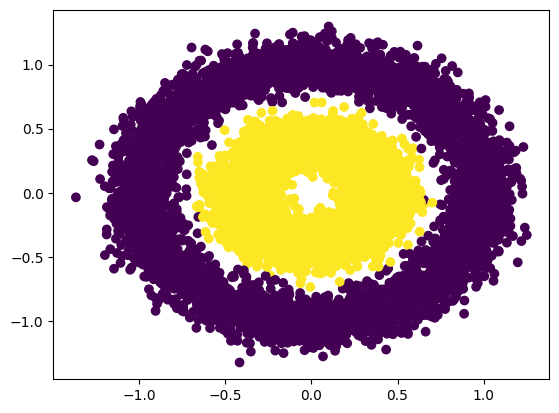

In [22]:
plt.scatter(X[:,0],X[:,1],c=y)

In [23]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()
clf.fit(X,y)

LogisticRegression()

<Axes: >

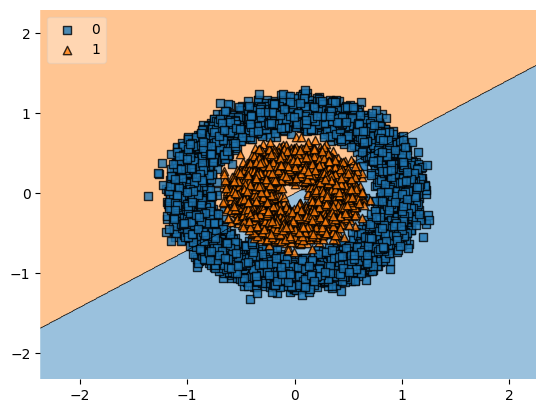

In [24]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X,y.astype('int'), clf, legend=2)

In [25]:
from sklearn.model_selection import cross_val_score
np.mean(cross_val_score(clf, X, y, scoring='accuracy', cv=10))

np.float64(0.48250000000000004)

In [44]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2, include_bias=False)

X_trf = poly.fit_transform(X)

In [45]:
clf1 = LogisticRegression()
np.mean(cross_val_score(clf1, X_trf, y, scoring='accuracy', cv=10))

np.float64(0.9987999999999999)

In [60]:
def plot_decision_boundary(X,y,degree=1):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_trf = poly.fit_transform(X)

    clf = LogisticRegression(max_iter=500)
    clf.fit(X_trf,y)
    
    scores = np.mean(cross_val_score(clf, X_trf, y, scoring='accuracy', cv=10))
    print(f"Mean CV accuracy (degree={degree}): {np.mean(scores):.3f}")

    a=np.arange(start=X[:,0].min()-1, stop=X[:,0].max()+1, step=0.01)
    b=np.arange(start=X[:,1].min()-1, stop=X[:,1].max()+1, step=0.01)


    XX,YY=np.meshgrid(a,b)
    
    input_array=np.array([XX.ravel(),YY.ravel()]).T

    labels=clf.predict(poly.transform(input_array))
    
    plt.contourf(XX,YY,labels.reshape(XX.shape),alpha=0.5)
    plt.scatter(X[:,0],X[:,1], c=y,marker='.')
    plt.title('Degree = {}, accuracy is {}'.format(degree,np.round(scores,4)))

    

Mean CV accuracy (degree=1): 0.483


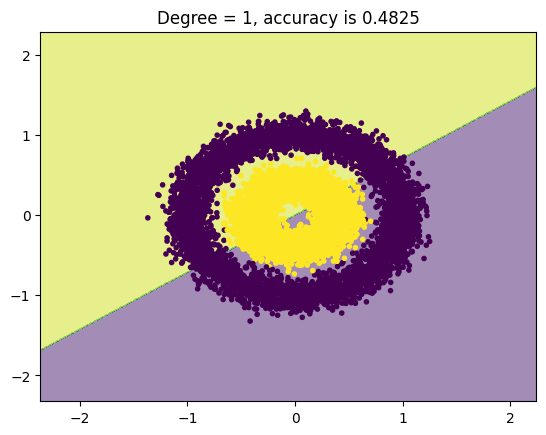

In [61]:
plot_decision_boundary(X,y)

Mean CV accuracy (degree=2): 0.999


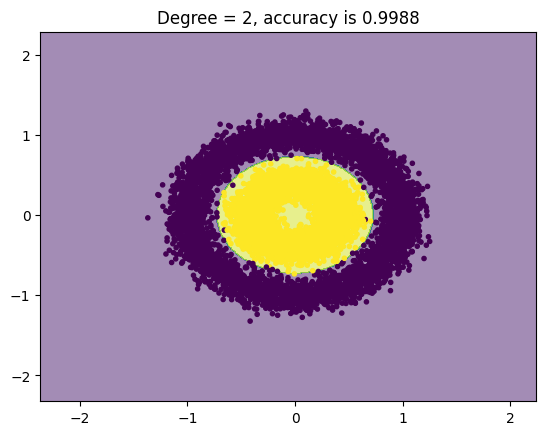

In [62]:
plot_decision_boundary(X,y,2)

Mean CV accuracy (degree=3): 0.999


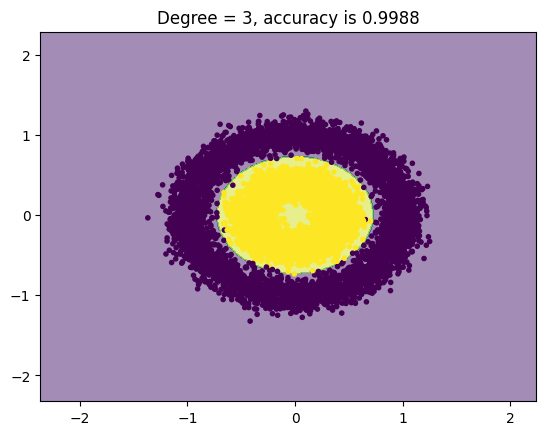

In [63]:
plot_decision_boundary(X,y,3)